#Loads libraries (including Pipeline and TF-IDF) and the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")

DATA_PATH = "Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)

Shape: (9551, 21)


# Takes the first cuisine as the label and keeps cuisines with at least MIN_ROWS restaurants

Distinct primary cuisines: 119
Kept 18 cuisines, 8361 restaurants


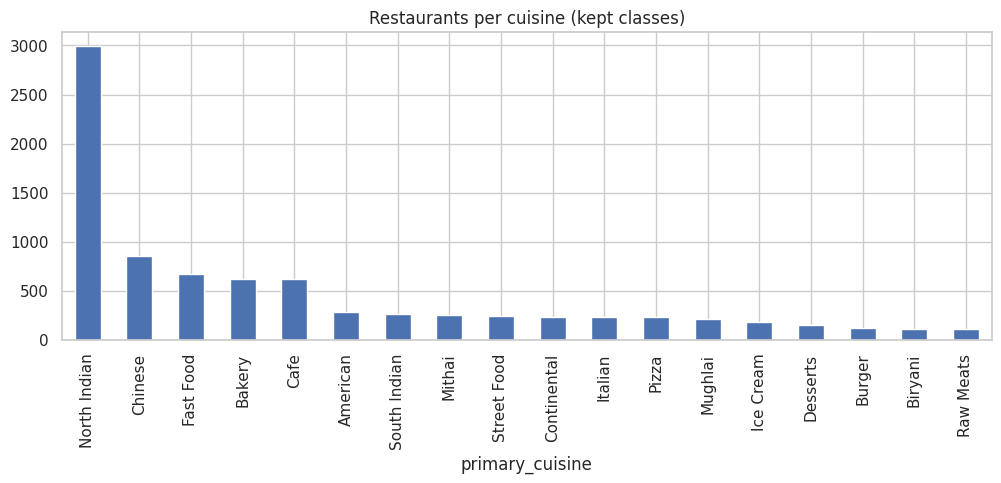

In [ ]:
df = df.dropna(subset=["Cuisines"]).copy()
df["primary_cuisine"] = df["Cuisines"].str.split(",").str[0].str.strip()

counts = df["primary_cuisine"].value_counts()
print("Distinct primary cuisines:", len(counts))

MIN_ROWS = 100
keep = counts[counts >= MIN_ROWS].index
data = df[df["primary_cuisine"].isin(keep)].copy()
print(f"Kept {len(keep)} cuisines, {len(data)} restaurants")

counts[keep].plot(kind="bar", figsize=(12, 4), title="Restaurants per cuisine (kept classes)")
plt.show()

# Accuracy of always guessing the most common cuisine

In [ ]:
baseline_acc = data["primary_cuisine"].value_counts(normalize=True).iloc[0]
print(f"Majority-class baseline accuracy: {baseline_acc:.3f}  "
      f"(always predict '{data['primary_cuisine'].value_counts().index[0]}')")

Majority-class baseline accuracy: 0.358  (always predict 'North Indian')


#TF-IDF on the restaurant name, scaled numeric features, one-hot country, stratified 80/20 split

In [ ]:
data["log_votes"] = np.log1p(data["Votes"])
data["has_table_booking"] = (data["Has Table booking"] == "Yes").astype(int)
data["has_online_delivery"] = (data["Has Online delivery"] == "Yes").astype(int)
data["country"] = data["Country Code"].astype(str)

num_cols = ["log_votes", "Price range", "has_table_booking", "has_online_delivery"]
X = data[["Restaurant Name", "country"] + num_cols]
y = data["primary_cuisine"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps class proportions

preprocess = ColumnTransformer([
    ("name", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "Restaurant Name"),
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["country"]),
])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6688, 6)  Test: (1673, 6)


#Logistic Regression, balanced Logistic Regression, Random Forest, each in a Pipeline

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=5),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, C=5, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
    })
    fitted[name] = (pipe, pred)

results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Baseline accuracy to beat: {baseline_acc:.3f}")
results

Baseline accuracy to beat: 0.358


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
model,,,,,
Logistic Regression,0.662,0.691,0.542,0.595,0.645
Logistic Regression (balanced),0.571,0.545,0.611,0.566,0.583
Random Forest,0.614,0.602,0.526,0.554,0.604


#F1 score for each cuisine

Best model by macro F1: Logistic Regression


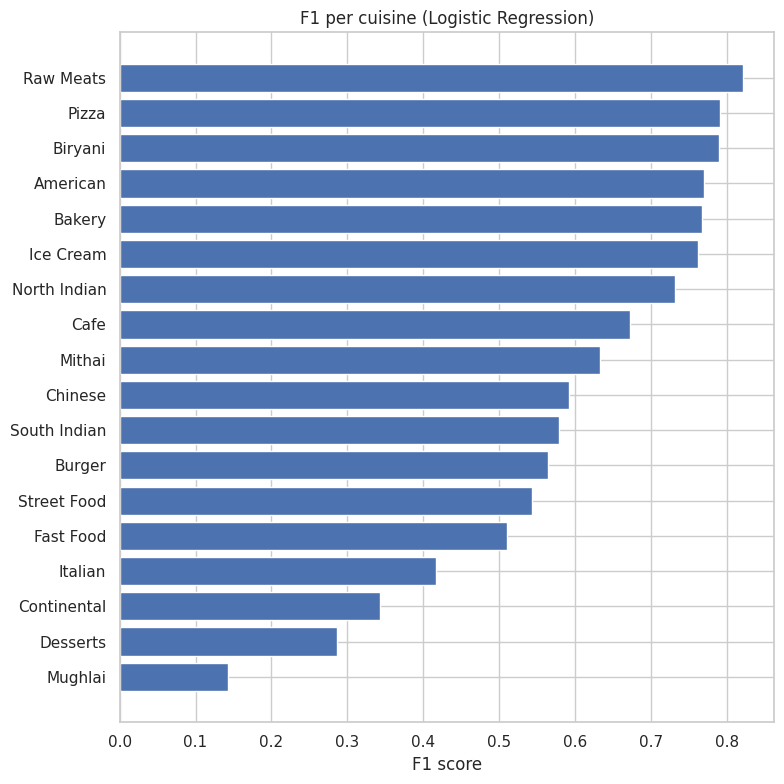

,precision,recall,f1-score,support
Mughlai,0.31,0.09,0.14,43.0
Desserts,0.50,0.20,0.29,30.0
Continental,0.52,0.26,0.34,47.0
Italian,0.60,0.32,0.42,47.0
Fast Food,0.59,0.45,0.51,135.0
Street Food,0.65,0.47,0.54,47.0
Burger,0.69,0.48,0.56,23.0
South Indian,0.77,0.46,0.58,52.0
Chinese,0.68,0.52,0.59,171.0
Mithai,0.63,0.63,0.63,49.0


In [ ]:
best_name = results["F1 (macro)"].idxmax()
best_pipe, best_pred = fitted[best_name]
print("Best model by macro F1:", best_name)

report = pd.DataFrame(classification_report(y_test, best_pred, output_dict=True, zero_division=0)).T
per_cuisine = report.drop(index=["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score")

plt.figure(figsize=(8, 8))
plt.barh(per_cuisine.index, per_cuisine["f1-score"])
plt.xlabel("F1 score")
plt.title(f"F1 per cuisine ({best_name})")
plt.tight_layout()
plt.show()

per_cuisine.round(2)

#Shows which cuisines get confused (top 10)
(A bright off-diagonal square means one cuisine is mistaken for another.)

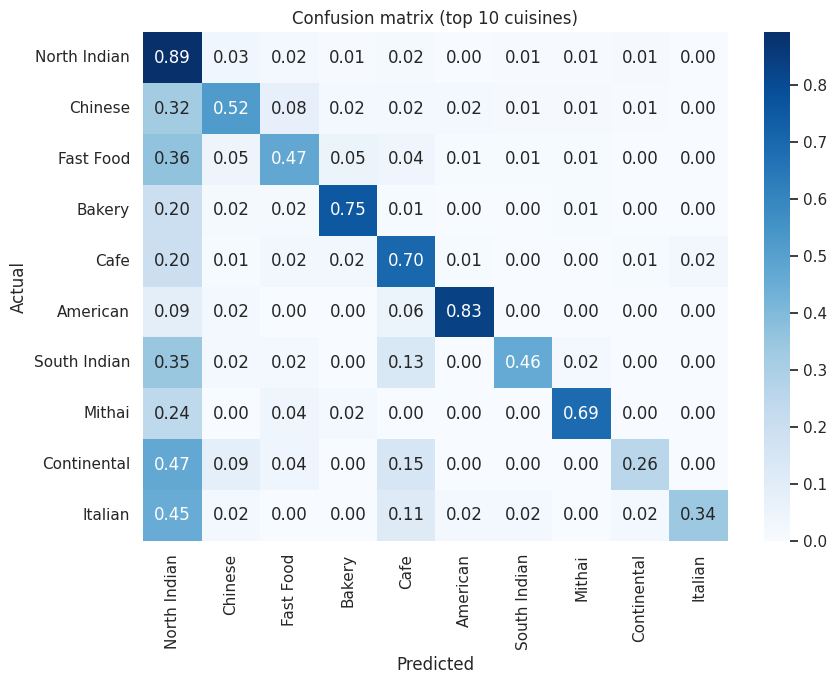

In [ ]:
top10 = y_test.value_counts().head(10).index
mask = y_test.isin(top10)
cm = confusion_matrix(y_test[mask], pd.Series(best_pred, index=y_test.index)[mask],
                      labels=top10, normalize="true")

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=top10, yticklabels=top10)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (top 10 cuisines)")
plt.tight_layout()
plt.show()

#Lists real wrong predictions

In [ ]:
errors = X_test.assign(actual=y_test, predicted=best_pred)
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} wrong out of {len(X_test)}")
errors[["Restaurant Name", "actual", "predicted"]].sample(12, random_state=1)

565 wrong out of 1673


,Restaurant Name,actual,predicted
2460,Crave Desserts & Bakes,Desserts,Bakery
1194,PizzaVito,Italian,North Indian
1468,19 Flavours Biryani,Mughlai,North Indian
4958,Le Belvedere - Le Meridien,Chinese,Cafe
4791,GO CHATZ With Breadz,Chinese,North Indian
1962,Dancing Turkeys,Continental,North Indian
8441,Hungry Minister,Continental,Fast Food
7621,Pat 'N' Harry,American,North Indian
1427,Oh! Fudge,Bakery,Chinese
5790,Biryani Express,Biryani,North Indian


# **Conclusion**

#**Best model:** Logistic Regression with restaurant-name TF-IDF performed best, reaching 66.2% accuracy and a macro F1 of 0.595, compared with a baseline of 35.8% for always predicting North Indian. Random Forest reached 61.4% accuracy.

#**Parameter change:** Earlier I changed MIN_ROWS from 50 to 100, which removed 8 rarer cuisines and left 18. Accuracy rose, but the baseline also rose (from 33.6% to 35.8%), so the real gain over the baseline stayed about the same (roughly 30 percentage points). The higher accuracy mainly reflects an easier problem.

#**Class balancing:** Using balanced class weights raised macro recall from 0.542 to 0.611 but lowered accuracy (57.1%) and precision. It finds more rare cuisines but makes more wrong guesses.

#**Per-cuisine performance:** Cuisines with distinctive name words, such as Raw Meats, Pizza, Biryani and Bakery, were classified well (F1 around 0.77 to 0.82). Mughlai (F1 0.14), Desserts (0.29) and Continental (0.34) were hardest because they overlap with other cuisines. In the error samples, for example, a Mughlai restaurant was predicted as North Indian.

#**Bias and challenges:** The model favours the majority class: North Indian has a recall of 0.87 but a precision of 0.63. Restaurants often serve several cuisines, so single-cuisine labels are noisy, and the dataset is dominated by Indian restaurants.

#**Next steps:** Multi-label classification using all listed cuisines, and gradient boosting.